# Tugas Hands-On 3: Pandas Lanjutan
**Kasus 08: Student Performance (EdTech)**, file `case9_student_performance.csv`, 800 baris, klasifikasi biner.
**Tujuan:** membersihkan data siswa, mencari faktor yang berkaitan dengan kelulusan, lalu menyiapkan data untuk memprediksi `status_kelulusan` (Lulus / Tidak Lulus) tanpa data leakage.

Urutan kerja: Data -> Kualitas -> Analisis -> Persiapan model -> Simpan hasil.

In [1]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

os.makedirs('data', exist_ok=True)
os.makedirs('output', exist_ok=True)
print('Library berhasil diimport')

Library berhasil diimport


## Tahap 1. Data
Dataset dimuat dari file `case9_student_performance.csv`. Urutan percobaan: (1) cari file di folder kerja, (2) kalau belum ada, coba unduh langsung dari Google Sheets, (3) kalau gagal, Colab akan meminta file di-upload manual. Salinan data asli disimpan di folder `data/` dan tidak diubah.

In [2]:
NAMA_FILE = 'case9_student_performance.csv'
SHEET_ID  = '1-7RVtr_yZdilG4nurXmSjvvTyDqBLgM7TWo2kmFe-Gg'
URL_CSV   = f'https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv'

def muat_data():
    # 1. file sudah ada di folder kerja atau di folder data/
    for lokasi in [NAMA_FILE, f'data/{NAMA_FILE}']:
        if os.path.exists(lokasi):
            print('Membaca file lokal:', lokasi)
            return pd.read_csv(lokasi)
    # 2. unduh langsung dari Google Sheets (harus bisa diakses publik)
    try:
        d = pd.read_csv(URL_CSV)
        assert 'student_id' in d.columns
        d.to_csv(NAMA_FILE, index=False)
        print('Berhasil diunduh dari Google Sheets')
        return d
    except Exception as e:
        print('Unduh otomatis gagal, silakan upload file CSV secara manual.')
    # 3. upload manual (khusus Colab)
    from google.colab import files
    files.upload()
    return pd.read_csv(NAMA_FILE)

df = muat_data()
df_mentah = df.copy()                       # salinan data mentah untuk perbandingan
os.makedirs('data', exist_ok=True)
if os.path.exists(NAMA_FILE):
    shutil.copy(NAMA_FILE, f'data/{NAMA_FILE}')   # dataset asli untuk folder pengumpulan

print('Shape:', df.shape)
df.info()

Membaca file lokal: case9_student_performance.csv
Shape: (800, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   student_id              800 non-null    object 
 1   usia                    778 non-null    float64
 2   jenis_kelamin           776 non-null    object 
 3   jenis_sekolah           779 non-null    object 
 4   pendidikan_orang_tua    773 non-null    object 
 5   pekerjaan_orang_tua     777 non-null    object 
 6   jam_belajar_per_minggu  773 non-null    float64
 7   persentase_kehadiran    774 non-null    float64
 8   ikut_ekskul             766 non-null    object 
 9   akses_internet          757 non-null    object 
 10  les_privat              776 non-null    object 
 11  waktu_tempuh_menit      770 non-null    float64
 12  nilai_matematika        768 non-null    float64
 13  nilai_bahasa_indonesia  769 

In [3]:
df.describe(include='all')

,student_id,usia,jenis_kelamin,jenis_sekolah,pendidikan_orang_tua,pekerjaan_orang_tua,jam_belajar_per_minggu,persentase_kehadiran,ikut_ekskul,akses_internet,les_privat,waktu_tempuh_menit,nilai_matematika,nilai_bahasa_indonesia,nilai_ipa,nilai_ips,nilai_bahasa_inggris,nilai_rata_rata,status_kelulusan
count,800,778.000000,776,779,773,777,773.000000,774.000000,766,757,776,770.000000,768.000000,769.000000,757.000000,769.000000,752.000000,775.000000,800
unique,800,NaN,2,2,5,6,NaN,NaN,2,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,STU0001,NaN,Laki-laki,Negeri,SMP,PNS,NaN,NaN,Tidak,Ya,Tidak,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Lulus
freq,1,NaN,399,394,168,152,NaN,NaN,396,535,509,NaN,NaN,NaN,NaN,NaN,NaN,NaN,493
mean,NaN,14.840617,NaN,NaN,NaN,NaN,21.513583,71.814212,NaN,NaN,NaN,77.071429,71.006510,75.600780,68.597094,73.109233,67.128989,70.695484,NaN
std,NaN,2.046511,NaN,NaN,NaN,NaN,12.156850,15.866712,NaN,NaN,NaN,41.519906,19.902335,18.991515,20.438452,20.058730,22.223969,18.463492,NaN
min,NaN,12.000000,NaN,NaN,NaN,NaN,1.000000,45.000000,NaN,NaN,NaN,5.000000,18.000000,31.000000,13.000000,11.000000,0.000000,25.600000,NaN
25%,NaN,13.000000,NaN,NaN,NaN,NaN,11.000000,57.300000,NaN,NaN,NaN,40.000000,56.000000,61.000000,53.000000,59.000000,51.000000,55.900000,NaN
50%,NaN,15.000000,NaN,NaN,NaN,NaN,21.000000,71.650000,NaN,NaN,NaN,78.500000,72.000000,77.000000,70.000000,74.000000,70.000000,71.600000,NaN
75%,NaN,17.000000,NaN,NaN,NaN,NaN,32.000000,85.200000,NaN,NaN,NaN,113.750000,87.000000,94.000000,85.000000,90.000000,86.000000,86.400000,NaN


Dari `info()` dan `describe()` ada beberapa hal yang perlu dicek lebih lanjut:
- Banyak kolom punya nilai kosong, termasuk kolom nilai mapel dan `nilai_rata_rata`.
- Ada kolom nilai (`nilai_matematika` sampai `nilai_bahasa_inggris`, dan `nilai_rata_rata`) yang berhubungan langsung dengan `status_kelulusan`. Ini penting untuk tahap persiapan model (bahaya data leakage).
- Perlu dicek apakah ada nilai di luar rentang wajar (nilai di atas 100, kehadiran di atas 100%, jam belajar yang tidak masuk akal).

In [4]:
# Nilai unik kolom kategorik, untuk mengecek penulisan yang tidak konsisten
kolom_kat = ['jenis_kelamin', 'jenis_sekolah', 'pendidikan_orang_tua', 'pekerjaan_orang_tua',
             'ikut_ekskul', 'akses_internet', 'les_privat', 'status_kelulusan']
for k in kolom_kat:
    print(k, '->', df[k].value_counts(dropna=False).to_dict())

jenis_kelamin -> {'Laki-laki': 399, 'Perempuan': 377, nan: 24}
jenis_sekolah -> {'Negeri': 394, 'Swasta': 385, nan: 21}
pendidikan_orang_tua -> {'SMP': 168, 'SD': 159, 'SMA': 151, 'S1': 148, 'S2': 147, nan: 27}
pekerjaan_orang_tua -> {'PNS': 152, 'Tidak Bekerja': 140, 'Petani': 129, 'Wiraswasta': 125, 'Karyawan Swasta': 116, 'Buruh': 115, nan: 23}
ikut_ekskul -> {'Tidak': 396, 'Ya': 370, nan: 34}
akses_internet -> {'Ya': 535, 'Tidak': 222, nan: 43}
les_privat -> {'Tidak': 509, 'Ya': 267, nan: 24}
status_kelulusan -> {'Lulus': 493, 'Tidak Lulus': 307}


## Tahap 2. Kualitas Data
Fungsi `cek_kualitas` meringkas jumlah baris, duplikat (berdasarkan `student_id`), missing value, dan outlier IQR pada `jam_belajar_per_minggu` per `jenis_sekolah`. Outlier dihitung per jenis sekolah supaya perbandingannya adil antara sekolah negeri dan swasta.

In [5]:
def cek_kualitas(d, kolom_num, kolom_grup, kunci):
    """Ringkasan kualitas data: baris, duplikat, missing, dan outlier IQR per grup."""
    g  = d.groupby(kolom_grup, observed=True)[kolom_num]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    outlier = (d[kolom_num] < q1 - 1.5 * iqr) | (d[kolom_num] > q3 + 1.5 * iqr)
    return pd.Series({
        'n_baris':    len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing':  d.isnull().sum().sum(),
        'n_outlier':  outlier.sum(),
    })

cek_kualitas(df_mentah, 'jam_belajar_per_minggu', 'jenis_sekolah', 'student_id')

,0
n_baris,800
n_duplikat,0
n_missing,511
n_outlier,0


In [6]:
# Missing value per kolom pada data mentah
mv = df_mentah.isnull().sum()
pd.DataFrame({'n_missing': mv, 'persen': (mv / len(df_mentah) * 100).round(1)})[mv > 0]

,n_missing,persen
usia,22,2.8
jenis_kelamin,24,3.0
jenis_sekolah,21,2.6
pendidikan_orang_tua,27,3.4
pekerjaan_orang_tua,23,2.9
jam_belajar_per_minggu,27,3.4
persentase_kehadiran,26,3.2
ikut_ekskul,34,4.2
akses_internet,43,5.4
les_privat,24,3.0


### Pembersihan (urutan: duplikat -> missing value -> outlier -> tipe data)

**1. Duplikat.** Satu `student_id` hanya boleh mewakili satu siswa, jadi baris dengan `student_id` yang sama dibuang dan yang pertama dipertahankan. Teks pada kolom kategorik juga dirapikan (spasi di awal dan akhir dibuang) supaya nilai yang sama tidak dianggap berbeda.

In [7]:
df_bersih = df_mentah.copy()

# rapikan teks: buang spasi berlebih
kolom_teks = ['student_id'] + kolom_kat
for k in kolom_teks:
    df_bersih[k] = df_bersih[k].astype('object').where(df_bersih[k].isna(), df_bersih[k].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True))

for k in ['ikut_ekskul', 'akses_internet', 'les_privat', 'jenis_sekolah']:
    df_bersih[k] = df_bersih[k].str.capitalize()    # 'ya' / 'YA' -> 'Ya'

n_awal = len(df_bersih)
df_bersih = df_bersih.drop_duplicates(subset='student_id', keep='first').reset_index(drop=True)
print(f'Baris duplikat dibuang: {n_awal - len(df_bersih)} | sisa: {len(df_bersih)}')

# periksa ulang penulisan kategori setelah dirapikan
for k in ['jenis_kelamin', 'jenis_sekolah', 'status_kelulusan']:
    print(k, '->', df_bersih[k].value_counts(dropna=False).to_dict())

Baris duplikat dibuang: 0 | sisa: 800
jenis_kelamin -> {'Laki-laki': 399, 'Perempuan': 377, nan: 24}
jenis_sekolah -> {'Negeri': 394, 'Swasta': 385, nan: 21}
status_kelulusan -> {'Lulus': 493, 'Tidak Lulus': 307}


**2. Missing value.** Keputusan per kelompok kolom:

- **`status_kelulusan` (target):** baris tanpa target dibuang karena tidak bisa dipakai untuk belajar maupun evaluasi.
- **Kolom nilai:** `nilai_rata_rata` seharusnya rata-rata dari lima nilai mapel. Asumsi ini saya uji dulu pada baris yang lengkap. Kalau benar, nilai yang hilang bisa dipulihkan dari baris yang sama (bukan dari statistik data lain, jadi tidak ada leakage antar baris): rata-rata dihitung dari lima mapel, dan satu mapel yang kosong dihitung mundur dari rata-rata. Nilai di luar rentang 0 sampai 100 dianggap tidak valid dan dijadikan kosong dulu sebelum dipulihkan.
- **Kolom lain (usia, jam belajar, kehadiran, kategorik, dan sebagainya):** sengaja **tidak diisi di sini**. Pengisian median dan modus dilakukan di `ColumnTransformer` setelah split, supaya statistiknya dihitung dari data train saja.

In [8]:
mapel = ['nilai_matematika', 'nilai_bahasa_indonesia', 'nilai_ipa', 'nilai_ips', 'nilai_bahasa_inggris']
kolom_nilai = mapel + ['nilai_rata_rata']

# pastikan numerik; nilai di luar 0-100 dianggap tidak valid
for k in kolom_nilai:
    df_bersih[k] = pd.to_numeric(df_bersih[k], errors='coerce')
    tidak_valid = (df_bersih[k] < 0) | (df_bersih[k] > 100)
    print(f'{k}: nilai tidak valid -> {int(tidak_valid.sum())}')
    df_bersih.loc[tidak_valid, k] = np.nan

# uji asumsi: apakah nilai_rata_rata = rata-rata lima mapel pada baris yang lengkap?
lengkap = df_bersih[kolom_nilai].notna().all(axis=1)
cocok = (df_bersih.loc[lengkap, mapel].mean(axis=1).round(1) - df_bersih.loc[lengkap, 'nilai_rata_rata']).abs() < 0.11
print(f'Asumsi rata-rata benar pada {cocok.mean()*100:.1f}% dari {int(lengkap.sum())} baris lengkap')

nilai_matematika: nilai tidak valid -> 0
nilai_bahasa_indonesia: nilai tidak valid -> 0
nilai_ipa: nilai tidak valid -> 0
nilai_ips: nilai tidak valid -> 0
nilai_bahasa_inggris: nilai tidak valid -> 0
nilai_rata_rata: nilai tidak valid -> 0
Asumsi rata-rata benar pada 100.0% dari 610 baris lengkap


In [9]:
# 1) target kosong -> baris dibuang
n_sebelum = len(df_bersih)
df_bersih = df_bersih.dropna(subset=['status_kelulusan']).reset_index(drop=True)
print('Baris tanpa target dibuang:', n_sebelum - len(df_bersih))

# 2) rata-rata kosong tapi kelima mapel ada -> hitung dari mapel
m_rata = df_bersih['nilai_rata_rata'].isna() & df_bersih[mapel].notna().all(axis=1)
df_bersih.loc[m_rata, 'nilai_rata_rata'] = df_bersih.loc[m_rata, mapel].mean(axis=1).round(1)
print('nilai_rata_rata dihitung dari mapel:', int(m_rata.sum()))

# 3) tepat satu mapel kosong dan rata-rata ada -> hitung mundur
satu_kosong = (df_bersih[mapel].isna().sum(axis=1) == 1) & df_bersih['nilai_rata_rata'].notna()
dipulihkan = 0
for k in mapel:
    m = satu_kosong & df_bersih[k].isna()
    lainnya = [x for x in mapel if x != k]
    hasil = (5 * df_bersih.loc[m, 'nilai_rata_rata'] - df_bersih.loc[m, lainnya].sum(axis=1)).round()
    valid = hasil.between(0, 100)
    df_bersih.loc[hasil.index[valid], k] = hasil[valid]
    dipulihkan += int(valid.sum())
print('Nilai mapel dipulihkan dari rata-rata:', dipulihkan)

print('\nMissing tersisa pada kolom nilai:')
print(df_bersih[kolom_nilai].isnull().sum())

Baris tanpa target dibuang: 0
nilai_rata_rata dihitung dari mapel: 20
Nilai mapel dipulihkan dari rata-rata: 150

Missing tersisa pada kolom nilai:
nilai_matematika          8
nilai_bahasa_indonesia    6
nilai_ipa                 8
nilai_ips                 5
nilai_bahasa_inggris      8
nilai_rata_rata           5
dtype: int64


**3. Outlier.** Tiga kolom numerik diperiksa dengan aturan IQR per `jenis_sekolah`, lalu nilai yang melewati batas dipotong (*clip*) ke batas tersebut. Baris tidak dibuang karena siswanya tetap data yang sah, hanya angkanya yang janggal. Selain IQR, persentase kehadiran dipaksa berada di rentang 0 sampai 100 dan usia di rentang 5 sampai 25 tahun (di luar itu dianggap salah input dan dikosongkan, nanti diisi di pipeline).

In [10]:
kolom_outlier = ['jam_belajar_per_minggu', 'persentase_kehadiran', 'waktu_tempuh_menit']
for k in kolom_outlier:
    df_bersih[k] = pd.to_numeric(df_bersih[k], errors='coerce')
df_bersih['usia'] = pd.to_numeric(df_bersih['usia'], errors='coerce')

# aturan domain
salah_hadir = (df_bersih['persentase_kehadiran'] < 0) | (df_bersih['persentase_kehadiran'] > 100)
salah_usia  = (df_bersih['usia'] < 5) | (df_bersih['usia'] > 25)
salah_jam   = (df_bersih['jam_belajar_per_minggu'] < 0) | (df_bersih['jam_belajar_per_minggu'] > 168)
salah_tempuh = df_bersih['waktu_tempuh_menit'] < 0
print('Kehadiran tidak valid:', int(salah_hadir.sum()), '| usia tidak valid:', int(salah_usia.sum()),
      '| jam belajar tidak valid:', int(salah_jam.sum()), '| waktu tempuh negatif:', int(salah_tempuh.sum()))
df_bersih.loc[salah_hadir, 'persentase_kehadiran'] = np.nan
df_bersih.loc[salah_usia, 'usia'] = np.nan
df_bersih.loc[salah_jam, 'jam_belajar_per_minggu'] = np.nan
df_bersih.loc[salah_tempuh, 'waktu_tempuh_menit'] = np.nan

# IQR per jenis_sekolah (baris tanpa jenis_sekolah memakai batas dari seluruh data)
for k in kolom_outlier:
    g = df_bersih.groupby('jenis_sekolah', observed=True)[k]
    q1 = g.transform(lambda s: s.quantile(0.25)).fillna(df_bersih[k].quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75)).fillna(df_bersih[k].quantile(0.75))
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    is_out = (df_bersih[k] < bawah) | (df_bersih[k] > atas)
    print(f'{k}: outlier IQR yang dipotong -> {int(is_out.sum())}')
    df_bersih[k] = df_bersih[k].clip(lower=bawah, upper=atas)

Kehadiran tidak valid: 0 | usia tidak valid: 0 | jam belajar tidak valid: 0 | waktu tempuh negatif: 0
jam_belajar_per_minggu: outlier IQR yang dipotong -> 0
persentase_kehadiran: outlier IQR yang dipotong -> 0
waktu_tempuh_menit: outlier IQR yang dipotong -> 0


**4. Tipe data.** Kolom kategorik diubah ke `category`, `usia` ke tipe bilangan bulat yang boleh kosong (`Int64`), dan target dibuat versi numeriknya (`is_lulus`: 1 jika Lulus). Kolom turunan untuk analisis ditambahkan setelah ini.

In [11]:
for k in kolom_kat:
    df_bersih[k] = df_bersih[k].astype('category')
df_bersih['usia'] = df_bersih['usia'].round().astype('Int64')
for k in mapel:
    df_bersih[k] = df_bersih[k].astype('Float64').round(0)

df_bersih['is_lulus'] = (df_bersih['status_kelulusan'] == 'Lulus').astype(int)
print(df_bersih.dtypes)

student_id                  object
usia                         Int64
jenis_kelamin             category
jenis_sekolah             category
pendidikan_orang_tua      category
pekerjaan_orang_tua       category
jam_belajar_per_minggu     float64
persentase_kehadiran       float64
ikut_ekskul               category
akses_internet            category
les_privat                category
waktu_tempuh_menit         float64
nilai_matematika           Float64
nilai_bahasa_indonesia     Float64
nilai_ipa                  Float64
nilai_ips                  Float64
nilai_bahasa_inggris       Float64
nilai_rata_rata            float64
status_kelulusan          category
is_lulus                     int64
dtype: object


### Laporan kualitas: sebelum vs sesudah

In [12]:
laporan = pd.DataFrame({
    'sebelum': cek_kualitas(df_mentah, 'jam_belajar_per_minggu', 'jenis_sekolah', 'student_id'),
    'sesudah': cek_kualitas(df_bersih, 'jam_belajar_per_minggu', 'jenis_sekolah', 'student_id'),
})
laporan

,sebelum,sesudah
n_baris,800,800
n_duplikat,0,0
n_missing,511,341
n_outlier,0,0


In [13]:
sb, ss = laporan['sebelum'], laporan['sesudah']
print(f"Baris   : {sb['n_baris']} -> {ss['n_baris']}")
print(f"Duplikat: {sb['n_duplikat']} -> {ss['n_duplikat']}")
print(f"Missing : {sb['n_missing']} -> {ss['n_missing']}")
print(f"Outlier : {sb['n_outlier']} -> {ss['n_outlier']}  (jam belajar per minggu, IQR per jenis sekolah)")
print()
if sb['n_duplikat'] == 0:
    print('- Tidak ada duplikat student_id pada data mentah, jadi tidak ada baris yang dibuang pada langkah duplikat.')
else:
    print(f"- {sb['n_duplikat'] - ss['n_duplikat']} baris duplikat dibuang.")
if sb['n_outlier'] == 0:
    print('- Tidak ada outlier jam belajar menurut aturan IQR. Rentang datanya memang wajar, jadi tidak ada nilai yang dipotong.')
else:
    print(f"- Outlier turun dari {sb['n_outlier']} menjadi {ss['n_outlier']} setelah dipotong ke batas IQR.")
if ss['n_missing'] < sb['n_missing']:
    print(f"- Missing berkurang {sb['n_missing'] - ss['n_missing']} sel karena nilai mapel dan rata-rata dipulihkan dari baris yang sama.")
print(f"- Sisa {ss['n_missing']} sel kosong (usia, jam belajar, kehadiran, kategorik, dan nilai yang tidak bisa dipulihkan) sengaja diisi di pipeline setelah split agar tidak ada leakage.")

Baris   : 800 -> 800
Duplikat: 0 -> 0
Missing : 511 -> 341
Outlier : 0 -> 0  (jam belajar per minggu, IQR per jenis sekolah)

- Tidak ada duplikat student_id pada data mentah, jadi tidak ada baris yang dibuang pada langkah duplikat.
- Tidak ada outlier jam belajar menurut aturan IQR. Rentang datanya memang wajar, jadi tidak ada nilai yang dipotong.
- Missing berkurang 170 sel karena nilai mapel dan rata-rata dipulihkan dari baris yang sama.
- Sisa 341 sel kosong (usia, jam belajar, kehadiran, kategorik, dan nilai yang tidak bisa dipulihkan) sengaja diisi di pipeline setelah split agar tidak ada leakage.


**Interpretasi:** tulis ulang hasil di atas dengan kalimatmu sendiri di sel ini. Angka nol pada duplikat atau outlier bukan berarti pemeriksaannya sia-sia. Itu adalah temuan: datanya sudah bersih pada aspek tersebut, dan keputusan "tidak ada yang perlu dibuang" harus dijelaskan.

## Tahap 3. Analisis
**Catatan penyesuaian:** dataset ini tidak punya kolom tanggal dan tidak berisi transaksi pelanggan, jadi analisis **time series dan RFM dilewati**. Sebagai gantinya analisis difokuskan pada groupby lanjutan, binning, pivot, reshape (`melt`), dan korelasi untuk mencari faktor yang berkaitan dengan kelulusan.

### 3.1 Ringkasan kelulusan secara umum

In [14]:
print(df_bersih['status_kelulusan'].value_counts())
print(f"\nTingkat kelulusan keseluruhan: {df_bersih['is_lulus'].mean()*100:.1f}%")

ringkas_status = df_bersih.groupby('status_kelulusan', observed=True).agg(
    jumlah          = ('student_id', 'count'),
    rata_jam_belajar= ('jam_belajar_per_minggu', 'mean'),
    rata_kehadiran  = ('persentase_kehadiran', 'mean'),
    rata_tempuh     = ('waktu_tempuh_menit', 'mean'),
    rata_nilai      = ('nilai_rata_rata', 'mean'),
).round(1)
ringkas_status

status_kelulusan
Lulus          493
Tidak Lulus    307
Name: count, dtype: int64

Tingkat kelulusan keseluruhan: 61.6%


,jumlah,rata_jam_belajar,rata_kehadiran,rata_tempuh,rata_nilai
status_kelulusan,,,,,
Lulus,493,28.9,74.5,76.9,83.5
Tidak Lulus,307,9.5,67.5,77.4,50.9


### 3.2 Binning dan tingkat kelulusan per kelompok
Kolom numerik dibagi ke kelompok supaya mudah dibandingkan.

In [15]:
da = df_bersih.copy()
da['kelompok_jam']    = pd.cut(da['jam_belajar_per_minggu'], bins=[-1, 10, 20, 30, 1000],
                               labels=['0-10 jam', '11-20 jam', '21-30 jam', '>30 jam'])
da['kelompok_hadir']  = pd.cut(da['persentase_kehadiran'], bins=[-1, 60, 75, 90, 100],
                               labels=['<=60%', '61-75%', '76-90%', '>90%'])
da['kelompok_tempuh'] = pd.cut(da['waktu_tempuh_menit'], bins=[-1, 30, 60, 120, 10000],
                               labels=['<=30 mnt', '31-60 mnt', '61-120 mnt', '>120 mnt'])

for k in ['kelompok_jam', 'kelompok_hadir', 'kelompok_tempuh']:
    t = da.groupby(k, observed=True)['is_lulus'].agg(jumlah='count', tingkat_lulus='mean')
    t['tingkat_lulus'] = (t['tingkat_lulus'] * 100).round(1)
    print(t, '\n')

              jumlah  tingkat_lulus
kelompok_jam                       
0-10 jam         177            3.4
11-20 jam        196           42.9
21-30 jam        177           93.2
>30 jam          223           99.6 

                jumlah  tingkat_lulus
kelompok_hadir                       
<=60%              235           46.4
61-75%             198           62.6
76-90%             212           67.0
>90%               129           77.5 

                 jumlah  tingkat_lulus
kelompok_tempuh                       
<=30 mnt            129           56.6
31-60 mnt           168           63.7
61-120 mnt          314           63.7
>120 mnt            159           59.1 



### 3.3 Faktor kategorik: groupby per kelompok

In [16]:
faktor_kat = ['jenis_sekolah', 'jenis_kelamin', 'pendidikan_orang_tua', 'pekerjaan_orang_tua',
              'ikut_ekskul', 'akses_internet', 'les_privat']
for k in faktor_kat:
    t = da.groupby(k, observed=True)['is_lulus'].agg(jumlah='count', tingkat_lulus='mean')
    t['tingkat_lulus'] = (t['tingkat_lulus'] * 100).round(1)
    print(t.sort_values('tingkat_lulus', ascending=False), '\n')

               jumlah  tingkat_lulus
jenis_sekolah                       
Negeri            394           62.9
Swasta            385           60.5 

               jumlah  tingkat_lulus
jenis_kelamin                       
Laki-laki         399           62.2
Perempuan         377           60.7 

                      jumlah  tingkat_lulus
pendidikan_orang_tua                       
S2                       147           68.0
SMP                      168           60.1
SD                       159           59.7
SMA                      151           59.6
S1                       148           59.5 

                     jumlah  tingkat_lulus
pekerjaan_orang_tua                       
PNS                     152           64.5
Karyawan Swasta         116           62.9
Tidak Bekerja           140           62.9
Wiraswasta              125           60.0
Petani                  129           58.9
Buruh                   115           57.4 

             jumlah  tingkat_lulus
ikut_eksk

### 3.4 Pivot: les privat x akses internet

akses_internet  Tidak    Ya
les_privat                 
Tidak            51.5  60.2
Ya               65.9  68.2


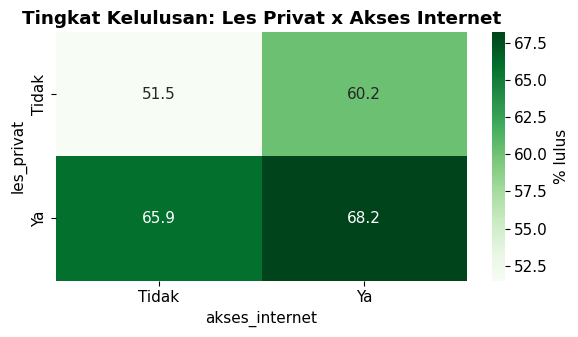

In [17]:
pivot = pd.pivot_table(da, values='is_lulus', index='les_privat', columns='akses_internet',
                       aggfunc='mean', observed=True).mul(100).round(1)
print(pivot)

plt.figure(figsize=(6, 3.5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Greens', cbar_kws={'label': '% lulus'})
plt.title('Tingkat Kelulusan: Les Privat x Akses Internet', fontweight='bold')
plt.tight_layout()
plt.show()

### 3.4b Pivot: jam belajar x kehadiran
Untuk melihat apakah kehadiran tinggi bisa "menyelamatkan" siswa yang jam belajarnya rendah.

% lulus:
kelompok_hadir  <=60%  61-75%  76-90%   >90%
kelompok_jam                                
0-10 jam          0.0     0.0     4.1   16.0
11-20 jam        11.5    41.3    59.6   76.7
21-30 jam        73.7    98.0   100.0  100.0
>30 jam          98.6   100.0   100.0  100.0

jumlah siswa:
kelompok_hadir  <=60%  61-75%  76-90%  >90%
kelompok_jam                               
0-10 jam           57      42      49    25
11-20 jam          61      46      52    30
21-30 jam          38      49      46    38
>30 jam            71      52      59    33


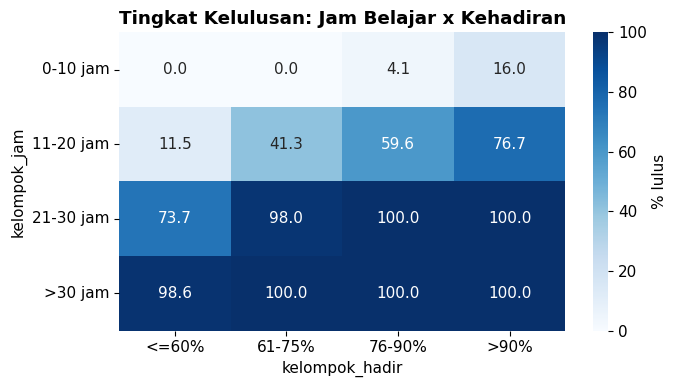

In [18]:
pivot_jh = pd.pivot_table(da, values='is_lulus', index='kelompok_jam', columns='kelompok_hadir',
                          aggfunc='mean', observed=True).mul(100).round(1)
jumlah_jh = pd.pivot_table(da, values='is_lulus', index='kelompok_jam', columns='kelompok_hadir',
                           aggfunc='count', observed=True)
print('% lulus:'); print(pivot_jh); print('\njumlah siswa:'); print(jumlah_jh)

plt.figure(figsize=(7, 4))
sns.heatmap(pivot_jh, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': '% lulus'})
plt.title('Tingkat Kelulusan: Jam Belajar x Kehadiran', fontweight='bold')
plt.tight_layout()
plt.show()

### 3.5 Reshape: rata-rata nilai tiap mapel per status
`melt` mengubah lima kolom nilai menjadi format panjang, lalu dibandingkan per status kelulusan.

status_kelulusan  Lulus  Tidak Lulus
mapel                               
Bahasa Indonesia   87.6         56.9
Bahasa Inggris     80.2         44.7
Ipa                81.0         48.3
Ips                85.3         53.1
Matematika         83.3         51.3


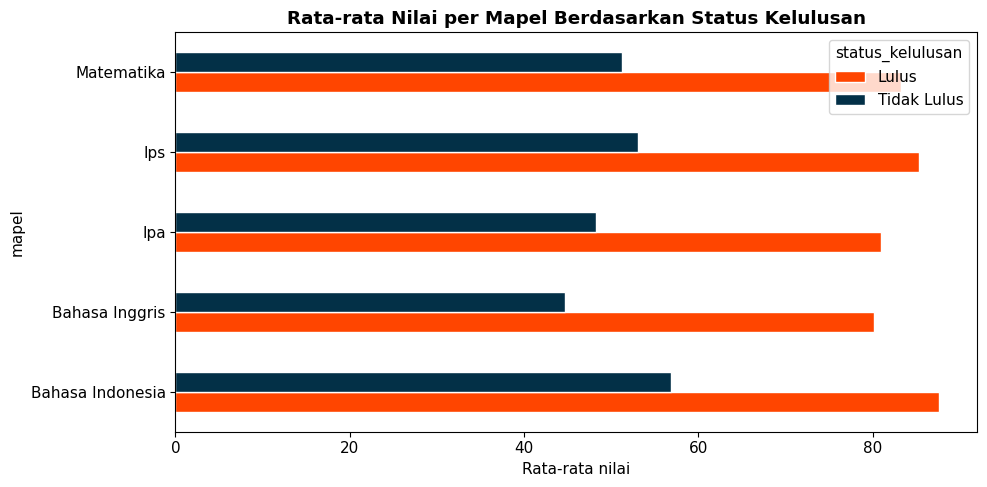

In [19]:
panjang = df_bersih.melt(id_vars=['student_id', 'status_kelulusan'], value_vars=mapel,
                         var_name='mapel', value_name='nilai')
panjang['mapel'] = panjang['mapel'].str.replace('nilai_', '').str.replace('_', ' ').str.title()
panjang['nilai'] = pd.to_numeric(panjang['nilai'])

rata_mapel = panjang.pivot_table(values='nilai', index='mapel', columns='status_kelulusan',
                                 aggfunc='mean', observed=True).round(1)
print(rata_mapel)

rata_mapel.plot(kind='barh', color=['#FF4500', '#033047'], edgecolor='white')
plt.title('Rata-rata Nilai per Mapel Berdasarkan Status Kelulusan', fontweight='bold')
plt.xlabel('Rata-rata nilai')
plt.tight_layout()
plt.show()

### 3.6 Korelasi antar fitur numerik
Korelasi ini hanya untuk analisis. Di tahap model, kolom nilai tidak dipakai sebagai fitur.

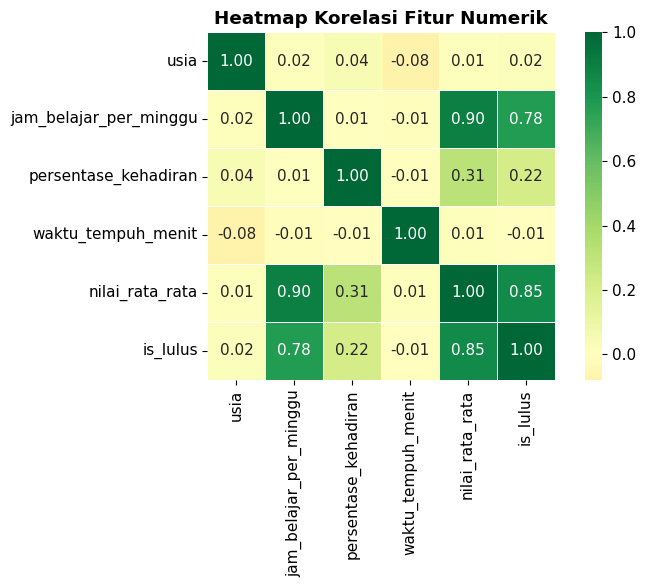

nilai_rata_rata           0.85
jam_belajar_per_minggu    0.78
persentase_kehadiran      0.22
usia                      0.02
waktu_tempuh_menit       -0.01
Name: is_lulus, dtype: float64


In [20]:
kolom_korelasi = ['usia', 'jam_belajar_per_minggu', 'persentase_kehadiran', 'waktu_tempuh_menit',
                  'nilai_rata_rata', 'is_lulus']
korelasi = df_bersih[kolom_korelasi].astype(float).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='RdYlGn', center=0, linewidths=0.5, square=True)
plt.title('Heatmap Korelasi Fitur Numerik', fontweight='bold')
plt.tight_layout()
plt.show()

print(korelasi['is_lulus'].drop('is_lulus').sort_values(key=abs, ascending=False).round(2))

### 3.7 Tiga temuan yang bisa ditindaklanjuti
Faktor diurutkan berdasarkan selisih tingkat kelulusan antara kelompok tertinggi dan terendah (hanya kelompok dengan minimal 30 siswa). Dua faktor teratas dijadikan temuan, ditambah satu temuan interaksi (kehadiran x jam belajar) bila datanya mendukung. Faktor dengan selisih di bawah 10 poin ditulis sebagai "bukan prioritas". **Baca hasilnya, lalu sesuaikan kalimatnya dengan gayamu sendiri** sebelum dikumpulkan.

In [21]:
nama_faktor = {
    'kelompok_jam': 'jam belajar per minggu', 'kelompok_hadir': 'persentase kehadiran',
    'kelompok_tempuh': 'waktu tempuh ke sekolah', 'jenis_sekolah': 'jenis sekolah',
    'jenis_kelamin': 'jenis kelamin', 'pendidikan_orang_tua': 'pendidikan orang tua',
    'pekerjaan_orang_tua': 'pekerjaan orang tua', 'ikut_ekskul': 'keikutsertaan ekskul',
    'akses_internet': 'akses internet', 'les_privat': 'les privat',
}
saran = {
    'kelompok_jam': 'buat program belajar terjadwal atau kelompok belajar bagi siswa pada kelompok {g}',
    'kelompok_hadir': 'pasang peringatan dini kehadiran dan hubungi orang tua siswa pada kelompok {g}',
    'kelompok_tempuh': 'beri materi daring atau jadwal fleksibel bagi siswa pada kelompok waktu tempuh {g}',
    'akses_internet': 'sediakan materi luring atau akses internet di sekolah bagi siswa pada kelompok {g}',
    'les_privat': 'sediakan bimbingan belajar tambahan di sekolah bagi siswa pada kelompok {g}',
    'ikut_ekskul': 'tinjau jadwal ekskul agar tidak mengganggu waktu belajar siswa pada kelompok {g}',
}

baris = []
for f in nama_faktor:
    t = da.groupby(f, observed=True)['is_lulus'].agg(['mean', 'count'])
    t = t[t['count'] >= 30]
    if len(t) < 2:
        continue
    baris.append({
        'faktor': f,
        'grup_tertinggi': str(t['mean'].idxmax()), 'lulus_tertinggi': t['mean'].max() * 100,
        'grup_terendah':  str(t['mean'].idxmin()), 'lulus_terendah':  t['mean'].min() * 100,
    })
ranking = pd.DataFrame(baris)
ranking['selisih'] = ranking['lulus_tertinggi'] - ranking['lulus_terendah']
ranking = ranking.sort_values('selisih', ascending=False).reset_index(drop=True)
print(ranking.round(1))

AMBANG = 10    # selisih di bawah 10 poin dianggap kecil
kalimat_rank = []
for i, r in ranking.iterrows():
    nm = nama_faktor[r['faktor']]
    if r['selisih'] >= AMBANG:
        pola = saran.get(r['faktor'], 'beri pendampingan khusus bagi siswa pada kelompok {g}')
        kalimat_rank.append(
            f"Faktor {nm} berkaitan dengan kelulusan: tingkat lulus tertinggi pada kelompok "
            f"{r['grup_tertinggi']} ({r['lulus_tertinggi']:.1f}%) dan terendah pada kelompok "
            f"{r['grup_terendah']} ({r['lulus_terendah']:.1f}%), selisih {r['selisih']:.1f} poin. "
            f"Tindak lanjut: {pola.format(g=r['grup_terendah'])}."
        )
    else:
        kalimat_rank.append(
            f"Faktor {nm} hanya menunjukkan selisih kecil ({r['selisih']:.1f} poin antara kelompok "
            f"{r['grup_tertinggi']} dan {r['grup_terendah']}). Tindak lanjut: faktor ini bukan prioritas "
            f"intervensi, sumber daya lebih baik diarahkan ke faktor dengan selisih besar."
        )

# temuan interaksi: kehadiran tinggi tetapi jam belajar rendah
rendah_tinggi = da[(da['kelompok_jam'] == '0-10 jam') & (da['kelompok_hadir'] == '>90%')]['is_lulus']
umum = da['is_lulus'].mean() * 100
kalimat_interaksi = None
if len(rendah_tinggi) >= 15 and rendah_tinggi.mean() * 100 < umum:
    kalimat_interaksi = (
        f"Kehadiran tinggi tidak menjamin kelulusan bila jam belajar rendah: siswa dengan kehadiran di atas 90% "
        f"tetapi belajar 0-10 jam per minggu hanya {rendah_tinggi.mean()*100:.1f}% yang lulus "
        f"(n = {len(rendah_tinggi)}), jauh di bawah rata-rata keseluruhan {umum:.1f}%. "
        f"Tindak lanjut: pantau jam belajar, bukan hanya absensi, saat mengidentifikasi siswa berisiko."
    )

temuan = kalimat_rank[:2]
temuan.append(kalimat_interaksi if kalimat_interaksi else kalimat_rank[2])

print()
for i, t in enumerate(temuan, 1):
    print(f'{i}. {t}\n')
print('Catatan: ini hubungan (korelasi), belum tentu sebab-akibat.')

                 faktor grup_tertinggi  lulus_tertinggi grup_terendah  \
0          kelompok_jam        >30 jam             99.6      0-10 jam   
1        kelompok_hadir           >90%             77.5         <=60%   
2            les_privat             Ya             67.4         Tidak   
3  pendidikan_orang_tua             S2             68.0            S1   
4       kelompok_tempuh     61-120 mnt             63.7      <=30 mnt   
5   pekerjaan_orang_tua            PNS             64.5         Buruh   
6        akses_internet             Ya             63.6         Tidak   
7         jenis_sekolah         Negeri             62.9        Swasta   
8           ikut_ekskul             Ya             62.4         Tidak   
9         jenis_kelamin      Laki-laki             62.2     Perempuan   

   lulus_terendah  selisih  
0             3.4     96.2  
1            46.4     31.1  
2            57.8      9.7  
3            59.5      8.6  
4            56.6      7.1  
5            57.4     

## Tahap 4. Persiapan Model
**Target:** `is_lulus` (1 = Lulus). **Metrik yang cocok** nanti adalah F1 atau recall kelas Tidak Lulus, bukan hanya akurasi.

**Data leakage yang sengaja dihindari:** `nilai_rata_rata` dan kelima nilai mapel **tidak dipakai sebagai fitur**. Status kelulusan ditentukan dari nilai rata-rata, jadi memasukkannya sama saja dengan memberi jawaban kepada model. Cek di bawah menunjukkan batas nilai antara dua kelas.

In [22]:
bukti = df_bersih.groupby('status_kelulusan', observed=True)['nilai_rata_rata'].agg(['min', 'max'])
print(bukti)
print('\nKalau kedua rentang hampir tidak tumpang tindih, nilai_rata_rata hampir pasti penentu kelulusan -> leakage.')

                   min    max
status_kelulusan             
Lulus             65.0  100.0
Tidak Lulus       25.6   64.8

Kalau kedua rentang hampir tidak tumpang tindih, nilai_rata_rata hampir pasti penentu kelulusan -> leakage.


**Fitur yang dipakai:** usia, jam belajar, kehadiran, waktu tempuh, jenis kelamin, jenis sekolah, pendidikan dan pekerjaan orang tua, ekskul, akses internet, dan les privat. `student_id` tidak dipakai karena hanya penanda baris.

**Urutan:** split dulu (dengan `stratify=y`), baru imputasi, scaling, dan encoding. Semuanya di-fit hanya pada data train.

In [23]:
fitur_num = ['usia', 'jam_belajar_per_minggu', 'persentase_kehadiran', 'waktu_tempuh_menit']
fitur_kat = ['jenis_kelamin', 'jenis_sekolah', 'pendidikan_orang_tua', 'pekerjaan_orang_tua',
             'ikut_ekskul', 'akses_internet', 'les_privat']

X = df_bersih[fitur_num + fitur_kat].copy()
X[fitur_num] = X[fitur_num].astype(float)
for k in fitur_kat:
    X[k] = X[k].astype(object)
X = X.where(X.notna(), np.nan)          # pastikan nilai kosong berupa NaN biasa
y = df_bersih['is_lulus']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Proporsi lulus train:', round(y_train.mean(), 4), '| test:', round(y_test.mean(), 4))

Train: (640, 11) | Test: (160, 11)
Proporsi lulus train: 0.6156 | test: 0.6188


In [24]:
preprocess = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
    ]), fitur_num),
    ('kat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot',  OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)),
    ]), fitur_kat),
])

X_train_p = preprocess.fit_transform(X_train)   # fit hanya di data train
X_test_p  = preprocess.transform(X_test)        # data test hanya ditransform

nama_fitur = list(preprocess.get_feature_names_out())
print('Shape train:', X_train_p.shape, '| test:', X_test_p.shape)
print('Missing setelah pipeline:', int(np.isnan(X_train_p).sum() + np.isnan(X_test_p).sum()))
print(nama_fitur)

Shape train: (640, 18) | test: (160, 18)
Missing setelah pipeline: 0
['num__usia', 'num__jam_belajar_per_minggu', 'num__persentase_kehadiran', 'num__waktu_tempuh_menit', 'kat__jenis_kelamin_Perempuan', 'kat__jenis_sekolah_Swasta', 'kat__pendidikan_orang_tua_S2', 'kat__pendidikan_orang_tua_SD', 'kat__pendidikan_orang_tua_SMA', 'kat__pendidikan_orang_tua_SMP', 'kat__pekerjaan_orang_tua_Karyawan Swasta', 'kat__pekerjaan_orang_tua_PNS', 'kat__pekerjaan_orang_tua_Petani', 'kat__pekerjaan_orang_tua_Tidak Bekerja', 'kat__pekerjaan_orang_tua_Wiraswasta', 'kat__ikut_ekskul_Ya', 'kat__akses_internet_Ya', 'kat__les_privat_Ya']


In [25]:
# Bukti tidak ada leakage: statistik berasal dari data train saja
imp = preprocess.named_transformers_['num'].named_steps['imputer']
sc  = preprocess.named_transformers_['num'].named_steps['scaler']
print('Median jam belajar (train, dipakai imputer):', imp.statistics_[1])
print('Median jam belajar (seluruh data)          :', X['jam_belajar_per_minggu'].median())
print('Rata-rata jam belajar (scaler, train)      :', round(sc.mean_[1], 2))
print('Rata-rata jam belajar (seluruh data)       :', round(X['jam_belajar_per_minggu'].mean(), 2))

Median jam belajar (train, dipakai imputer): 21.0
Median jam belajar (seluruh data)          : 21.0
Rata-rata jam belajar (scaler, train)      : 21.49
Rata-rata jam belajar (seluruh data)       : 21.51


## Simpan hasil
Output: `output/data_bersih.csv`, `output/kamus_data.csv`, `laporan_kualitas.csv`, dan `README.md`.

In [26]:
# data bersih (kolom analisis ikut disimpan)
df_bersih.to_csv('output/data_bersih.csv', index=False)

deskripsi = {
    'student_id': 'ID siswa (kunci unik)',
    'usia': 'Usia siswa (tahun)',
    'jenis_kelamin': 'Jenis kelamin',
    'jenis_sekolah': 'Negeri atau Swasta',
    'pendidikan_orang_tua': 'Pendidikan terakhir orang tua',
    'pekerjaan_orang_tua': 'Pekerjaan orang tua',
    'jam_belajar_per_minggu': 'Jam belajar per minggu (outlier dipotong per jenis sekolah)',
    'persentase_kehadiran': 'Persentase kehadiran (0-100)',
    'ikut_ekskul': 'Ikut ekstrakurikuler (Ya/Tidak)',
    'akses_internet': 'Punya akses internet (Ya/Tidak)',
    'les_privat': 'Ikut les privat (Ya/Tidak)',
    'waktu_tempuh_menit': 'Waktu tempuh ke sekolah (menit)',
    'nilai_matematika': 'Nilai matematika (0-100)',
    'nilai_bahasa_indonesia': 'Nilai bahasa Indonesia (0-100)',
    'nilai_ipa': 'Nilai IPA (0-100)',
    'nilai_ips': 'Nilai IPS (0-100)',
    'nilai_bahasa_inggris': 'Nilai bahasa Inggris (0-100)',
    'nilai_rata_rata': 'Rata-rata lima nilai mapel (TIDAK dipakai sebagai fitur, penyebab leakage)',
    'status_kelulusan': 'Lulus atau Tidak Lulus (target asli)',
    'is_lulus': 'Target numerik: 1 jika Lulus',
}
kamus = pd.DataFrame({
    'kolom':     df_bersih.columns,
    'tipe':      df_bersih.dtypes.astype(str).values,
    'n_missing': df_bersih.isnull().sum().values,
    'n_unik':    df_bersih.nunique().values,
    'deskripsi': [deskripsi.get(c, '') for c in df_bersih.columns],
})
kamus.to_csv('output/kamus_data.csv', index=False)

laporan.to_csv('laporan_kualitas.csv')
kamus

,kolom,tipe,n_missing,n_unik,deskripsi
0,student_id,object,0,800,ID siswa (kunci unik)
1,usia,Int64,22,7,Usia siswa (tahun)
2,jenis_kelamin,category,24,2,Jenis kelamin
3,jenis_sekolah,category,21,2,Negeri atau Swasta
4,pendidikan_orang_tua,category,27,5,Pendidikan terakhir orang tua
5,pekerjaan_orang_tua,category,23,6,Pekerjaan orang tua
6,jam_belajar_per_minggu,float64,27,42,Jam belajar per minggu (outlier dipotong per j...
7,persentase_kehadiran,float64,26,415,Persentase kehadiran (0-100)
8,ikut_ekskul,category,34,2,Ikut ekstrakurikuler (Ya/Tidak)
9,akses_internet,category,43,2,Punya akses internet (Ya/Tidak)


In [ ]:

# SEL AKHIR: susun folder pengumpulan "tugas-hands-on-3/" + README + zip
import os, json, shutil

# ---- Identitas  ----
NAMA  = 'M.Daffa S.F.P.N'
KELAS = 'RM 24 A'
NIM   = '24552011326'

FOLDER = 'tugas-hands-on-3'
if os.path.exists(FOLDER):
    shutil.rmtree(FOLDER)                       # mulai dari folder bersih
os.makedirs(f'{FOLDER}/data')
os.makedirs(f'{FOLDER}/output')

# ------------------------------------------------------------
# 1. Angka-angka untuk README (diambil otomatis dari hasil notebook)
# ------------------------------------------------------------
sb, ss = laporan['sebelum'], laporan['sesudah']
n_dup    = int(sb['n_duplikat'])
n_out    = int(sb['n_outlier'])
n_target = int(df_mentah['status_kelulusan'].isna().sum())
batas    = df_bersih.groupby('status_kelulusan', observed=True)['nilai_rata_rata'].agg(['min', 'max'])
min_lulus, max_tidak = batas.loc['Lulus', 'min'], batas.loc['Tidak Lulus', 'max']

ket_duplikat = (f'Ditemukan {n_dup} duplikat `student_id`, baris duplikat dibuang.' if n_dup
                else 'Tidak ada duplikat `student_id` (0 sebelum dan sesudah), jadi tidak ada baris yang dibuang.')
ket_target   = (f'Ada {n_target} baris tanpa `status_kelulusan`, baris tersebut dibuang.' if n_target
                else 'Tidak ada baris tanpa `status_kelulusan`, jadi tidak ada baris yang dibuang.')
ket_outlier  = (f'Aturan IQR per jenis sekolah menemukan {n_out} outlier pada jam belajar; nilainya dipotong ke batas IQR.' if n_out
                else 'Aturan IQR per jenis sekolah tidak menemukan outlier pada jam belajar, dan rentang data wajar, sehingga tidak ada nilai yang dipotong.')

# Temuan diambil dari sel analisis. Sebaiknya tulis ulang dengan kalimatmu sendiri.
daftar_temuan = '\n'.join(f'{i}. {t}' for i, t in enumerate(temuan, 1))

# ------------------------------------------------------------
# 2. Isi README.md
# ------------------------------------------------------------
readme = f'''**Nama :** {NAMA}  \n**Kelas :** {KELAS}  \n**NIM :** {NIM}

# Tugas Hands-On 3: Pandas Lanjutan

**Kasus:** 08 Student Performance (EdTech), file `{NAMA_FILE}` ({int(sb['n_baris'])} baris).
**Tujuan:** membersihkan data siswa, mencari faktor yang berkaitan dengan kelulusan, dan menyiapkan data untuk memprediksi `status_kelulusan` (Lulus / Tidak Lulus) tanpa data leakage.

## Ringkasan temuan
{daftar_temuan}

Catatan: temuan menunjukkan hubungan (korelasi), belum tentu sebab-akibat.

## Hasil audit kualitas data

| Ukuran | Sebelum | Sesudah |
|---|---:|---:|
| Jumlah baris | {int(sb['n_baris'])} | {int(ss['n_baris'])} |
| Duplikat | {n_dup} | {int(ss['n_duplikat'])} |
| Missing value (sel) | {int(sb['n_missing'])} | {int(ss['n_missing'])} |
| Outlier jam belajar | {n_out} | {int(ss['n_outlier'])} |

## Keputusan pembersihan
- **Duplikat:** {ket_duplikat}
- **Target kosong:** {ket_target}
- **Nilai mapel dan rata-rata yang kosong:** dipulihkan dari baris yang sama (rata-rata dihitung dari lima mapel, satu mapel yang kosong dihitung mundur dari rata-rata). Nilai di luar 0-100 dianggap tidak valid.
- **Missing value lainnya:** sengaja tidak diisi saat pembersihan. Diisi di pipeline setelah split (median untuk angka, modus untuk kategorik) dan hanya di-fit pada data train.
- **Outlier:** {ket_outlier}
- **Tipe data:** kolom kategorik diubah ke `category`, `usia` ke `Int64`, dan dibuat target numerik `is_lulus`.

## Data leakage
Nilai rata-rata terendah kelas Lulus adalah {min_lulus:.1f} dan tertinggi kelas Tidak Lulus adalah {max_tidak:.1f}, artinya `status_kelulusan` ditentukan oleh `nilai_rata_rata`. Karena itu `nilai_rata_rata` dan kelima nilai mapel **tidak dipakai sebagai fitur model**. Split dilakukan dengan `stratify=y` sebelum imputasi, scaling, dan encoding.

## Penyesuaian tugas
Time series dan RFM dilewati karena dataset tidak punya kolom tanggal maupun transaksi pelanggan. Analisis difokuskan pada groupby lanjutan, binning, pivot, reshape, dan korelasi.

## Cara menjalankan
1. Buka `notebook.ipynb` di Google Colab atau Jupyter.
2. Upload `{NAMA_FILE}` bila diminta.
3. Pilih Runtime -> Restart session and run all.

## Struktur folder
```
tugas-hands-on-3/
├── README.md
├── notebook.ipynb
├── laporan_kualitas.csv
├── data/
│   └── {NAMA_FILE}
└── output/
    ├── data_bersih.csv
    └── kamus_data.csv
```
'''
with open(f'{FOLDER}/README.md', 'w', encoding='utf-8') as f:
    f.write(readme)

# ------------------------------------------------------------
# 3. Salin file hasil ke struktur folder yang diminta tugas
# ------------------------------------------------------------
salinan = {
    'laporan_kualitas.csv':       f'{FOLDER}/laporan_kualitas.csv',
    f'data/{NAMA_FILE}':          f'{FOLDER}/data/{NAMA_FILE}',
    'output/data_bersih.csv':     f'{FOLDER}/output/data_bersih.csv',
    'output/kamus_data.csv':      f'{FOLDER}/output/kamus_data.csv',
}
for asal, tujuan in salinan.items():
    if os.path.exists(asal):
        shutil.copy(asal, tujuan)
    else:
        print(f'PERINGATAN: {asal} tidak ditemukan, jalankan dulu sel penyimpanan hasil.')

# ------------------------------------------------------------
# 4. Simpan notebook ini sendiri sebagai notebook.ipynb (khusus Colab)
# ------------------------------------------------------------
try:
    from google.colab import _message
    nb = _message.blocking_request('get_ipynb', request='', timeout_sec=60)['ipynb']
    with open(f'{FOLDER}/notebook.ipynb', 'w', encoding='utf-8') as f:
        json.dump(nb, f, ensure_ascii=False, indent=1)
    print('notebook.ipynb ikut tersimpan di folder.')
except Exception:
    print('PERHATIAN: notebook.ipynb belum masuk otomatis.\n'
          '  Unduh lewat File -> Download -> Download .ipynb, ubah namanya menjadi notebook.ipynb,\n'
          f'  lalu masukkan ke folder {FOLDER}/ secara manual.')

# ------------------------------------------------------------
# 5. Cek kelengkapan sesuai instruksi "Yang Dikumpulkan"
# ------------------------------------------------------------
wajib = ['README.md', 'notebook.ipynb', 'laporan_kualitas.csv',
         f'data/{NAMA_FILE}', 'output/data_bersih.csv', 'output/kamus_data.csv']
print('\nCek kelengkapan folder:')
for berkas in wajib:
    status = 'OK     ' if os.path.exists(f'{FOLDER}/{berkas}') else 'BELUM  '
    print(f'  [{status}] {FOLDER}/{berkas}')

# ------------------------------------------------------------
# 6. Zip (folder tugas-hands-on-3/ berada di dalam zip) lalu unduh
# ------------------------------------------------------------
shutil.make_archive(FOLDER, 'zip', root_dir='.', base_dir=FOLDER)
print(f'\n{FOLDER}.zip siap.')
try:
    from google.colab import files
    files.download(f'{FOLDER}.zip')
except ImportError:
    print('Bukan di Colab: zip tersimpan di folder kerja.')